# ETF comparison: IXN, QQQ and VOO

## Summary
QQQ leads IXN over the common history from IXN's November 12, 2001 launch. IXN leads over recent 1-, 3-, 5- and 10-year periods. IXN has greater global technology and semiconductor exposure, but substantially greater weight concentration than either QQQ or VOO.

## Context & Methods
All retrospective investment windows finish October 19, 2026. USD lump sum, dividends and capital gains reinvested, no contributions, taxes, trading costs or inflation adjustment. ETF returns already reflect historical fund expenses. We do not subtract current expenses again.

### Key assumptions and limitations
- IXN: official daily NAV and ex-distributions from inception to October 16; October 19 is appended using the observed market-price return. This last-day bridge is an estimate of NAV performance. NAV is adjusted for splits in the issuer download.
- VOO: S&P 500 total-return index minus an assumed 0.03% annual expense before its first public daily price, September 9, 2010, then actual VOO adjusted prices. This is a hypothetical index/ETF splice, not actual prelaunch VOO. Its fund inception was September 7.
- IXN before launch: Fidelity Select Technology (FSPTX), an actively managed technology mutual fund. It is a **regime proxy, not reconstructed IXN**, and does not reproduce global weights, classifications or costs.
- QQQ before March 10, 1999: Nasdaq-100 **price** index minus an assumed 0.20% annual expense. Prelaunch dividends are unavailable in these snapshots, so that segment understates a hypothetical total-return Nasdaq-100 portfolio. Do not call the 1990 comparison a total-return ETF backtest. A 0–0.5% assumed prelaunch dividend yield is examined separately.
- January 1 windows begin with the preceding available year-end close. IXN inception begins with the November 12 closing NAV. Returns are close-to-close.
- The strategy and stock-count models replay every requested start window. For 1990/2000, the exclusion changes apply **only after IXN launch**; the prelaunch FSPTX segment remains the same.
- Exclusion: the current 4.68% TSMC and 2.53% ASML weights are held constant and rebalanced monthly. Their USD listed-share/ADR adjusted returns proxy the local shares IXN owns. The residual basket is inferred algebraically from IXN. Actual historical weights, index constituents, taxes, local/ADR premia and fair-value adjustments are unavailable. It is an assumption sensitivity, **not historical stock attribution or an investable replica**. Exclusion removes losses as well as gains. A separate zero-return-cash variant keeps the unremoved sleeve's original exposure. The 0.37% annual fee is retained approximately in the reallocation model; exact historical fee schedules are unavailable.
- Count experiment: each observed monthly technology path is treated as a common factor. Add zero-mean independent individual-stock residuals with assumed 30% annual volatility, average over N equally weighted stocks, and replay 5,000 seeded paths. This isolates the consequence of changing stock count under an unchanged factor path. It is **not a portfolio of actual 1,200 companies**, and its 5th–95th percentiles are conditional model dispersion, not market-risk confidence bounds.
- Equicorrelation experiment assumes every stock has 35% annual volatility and common pairwise correlations of 0.2, 0.6 or 0.8; these are illustrative assumptions, not estimated correlations.
- Bootstrap: 10,000 paired paths, 12-month moving blocks, non-wrapping block starts; calibrations begin at each requested historical window and end with the last complete month, September 2026. Forward horizons are 1, 3, 5 and 10 years. Repeated historical blocks preserve some joint behavior but do not predict AI, valuation changes, structural breaks or geopolitical disasters. Block sampling is not uniform weighting of every individual endpoint month.
- Volatility uses daily simple returns and sqrt(252); drawdown uses daily wealth. Sharpe uses a fixed 3% annual hurdle for comparability, not realized T-bill returns. Overlapping rolling windows are not independent observations and win rates are not forecast probabilities.
- Concentration uses long equity positions only, normalized to 100%; duplicate issuer classes are combined (Alphabet, Samsung). IXN and QQQ holdings are October 16, VOO September 30. Holdings counts can differ from issuer accounting counts because cash, futures and share classes differ. HHI effective stock count = 1/sum(weight squared). It measures weight concentration, not independent risk factors. Stock overlap is matched by ticker with explicit mappings, not full economic/supply-chain overlap.
- Valuation and sector snapshots carry their own dates and provider definitions. IXN uses GICS and QQQ uses ICB, so displayed technology weights are not identical classification universes. IXN's P/E convention excludes loss-makers and caps individual P/E values at 60 in its factsheet definition.

## Data
`../sources/fetch_log.json` records public endpoints, source filenames and retrieval timestamps. `../fetch_data.py` downloads snapshots; `../analyze.py` is the calculation source. All CSV files here are derived from those snapshots. Data requires independent verification before trading; conclusions are research judgments and do not incorporate a personal portfolio or tax situation.


In [1]:
import sys, os
from pathlib import Path
root = Path.cwd().parent
sys.path.insert(0, str(root / 'vendor'))
sys.path.insert(0, str(root))
os.environ['MPLCONFIGDIR'] = str(root / 'outputs' / 'mpl-cache')
import pandas as pd, numpy as np, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image
import analyze
results = analyze.run()
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18,'figure.facecolor':'white'})
colors = ['#2d5b89','#b16a27','#687f45']


Reconciliation: {'months_checked': 298, 'largest_abs_monthly_error_bp': np.float64(2.7484985682785235), 'nav_bridge_date': '2026-10-19', 'nav_bridge_return': 0.01375845859233027}
       window fund     cagr  ending_10000  volatility  max_drawdown
         1990 IXN* 0.150502  1.741815e+06    0.258556     -0.839204
         1990 QQQ* 0.145722  1.494349e+06    0.259830     -0.829639
         1990 VOO* 0.108787  4.473741e+05    0.179314     -0.552692
         2000 IXN* 0.083563  8.592874e+04    0.263754     -0.839204
         2000 QQQ* 0.086937  9.339587e+04    0.267240     -0.829639
         2000 VOO* 0.082753  8.422303e+04    0.191682     -0.552692
IXN inception IXN* 0.124978  1.884657e+05    0.223151     -0.549669
IXN inception QQQ* 0.132916  2.245801e+05    0.228563     -0.534040
IXN inception VOO* 0.100232  1.082359e+05    0.189162     -0.552692
         2010 IXN* 0.184814  1.727052e+05    0.208931     -0.361420
         2010 QQQ* 0.188241  1.812924e+05    0.206347     -0.351187
     

## Results
### Returns and risk
Asterisks identify series that use a prelaunch proxy where needed. The pre-2001 technology proxy must not be interpreted as actual IXN.

In [2]:
history = pd.DataFrame(results['history'])
display(history[['window','fund','cagr','ending_10000','volatility','max_drawdown','dd_peak','dd_trough','recovered']].round(4))
display(pd.DataFrame(results['trailing'])[['horizon_years','fund','cagr','volatility','max_drawdown']].round(4))


,window,fund,cagr,ending_10000,volatility,max_drawdown,dd_peak,dd_trough,recovered
0,1990,IXN*,0.1505,1.741815e+06,0.2586,-0.8392,2000-03-10,2002-10-09,2017-10-27
1,1990,QQQ*,0.1457,1.494349e+06,0.2598,-0.8296,2000-03-27,2002-10-09,2015-02-20
2,1990,VOO*,0.1088,4.473741e+05,0.1793,-0.5527,2007-10-09,2009-03-09,2012-08-16
3,2000,IXN*,0.0836,8.592874e+04,0.2638,-0.8392,2000-03-10,2002-10-09,2017-10-27
4,2000,QQQ*,0.0869,9.339587e+04,0.2672,-0.8296,2000-03-27,2002-10-09,2015-02-20
5,2000,VOO*,0.0828,8.422303e+04,0.1917,-0.5527,2007-10-09,2009-03-09,2012-08-16
6,IXN inception,IXN*,0.1250,1.884657e+05,0.2232,-0.5497,2007-10-31,2009-03-09,2012-02-28
7,IXN inception,QQQ*,0.1329,2.245801e+05,0.2286,-0.5340,2007-10-31,2008-11-20,2010-12-08
8,IXN inception,VOO*,0.1002,1.082359e+05,0.1892,-0.5527,2007-10-09,2009-03-09,2012-08-16
9,2010,IXN*,0.1848,1.727052e+05,0.2089,-0.3614,2021-12-27,2022-10-12,2023-11-16


,horizon_years,fund,cagr,volatility,max_drawdown
0,1,IXN*,0.3391,0.2794,-0.1631
1,1,QQQ*,0.1940,0.1986,-0.1196
2,1,VOO*,0.1661,0.1267,-0.0890
3,3,IXN*,0.3411,0.2570,-0.2559
4,3,QQQ*,0.2660,0.2050,-0.2277
5,3,VOO*,0.2315,0.1485,-0.1869
6,5,IXN*,0.1921,0.2597,-0.3614
7,5,QQQ*,0.1454,0.2300,-0.3512
8,5,VOO*,0.1277,0.1690,-0.2452
9,10,IXN*,0.2345,0.2376,-0.3614


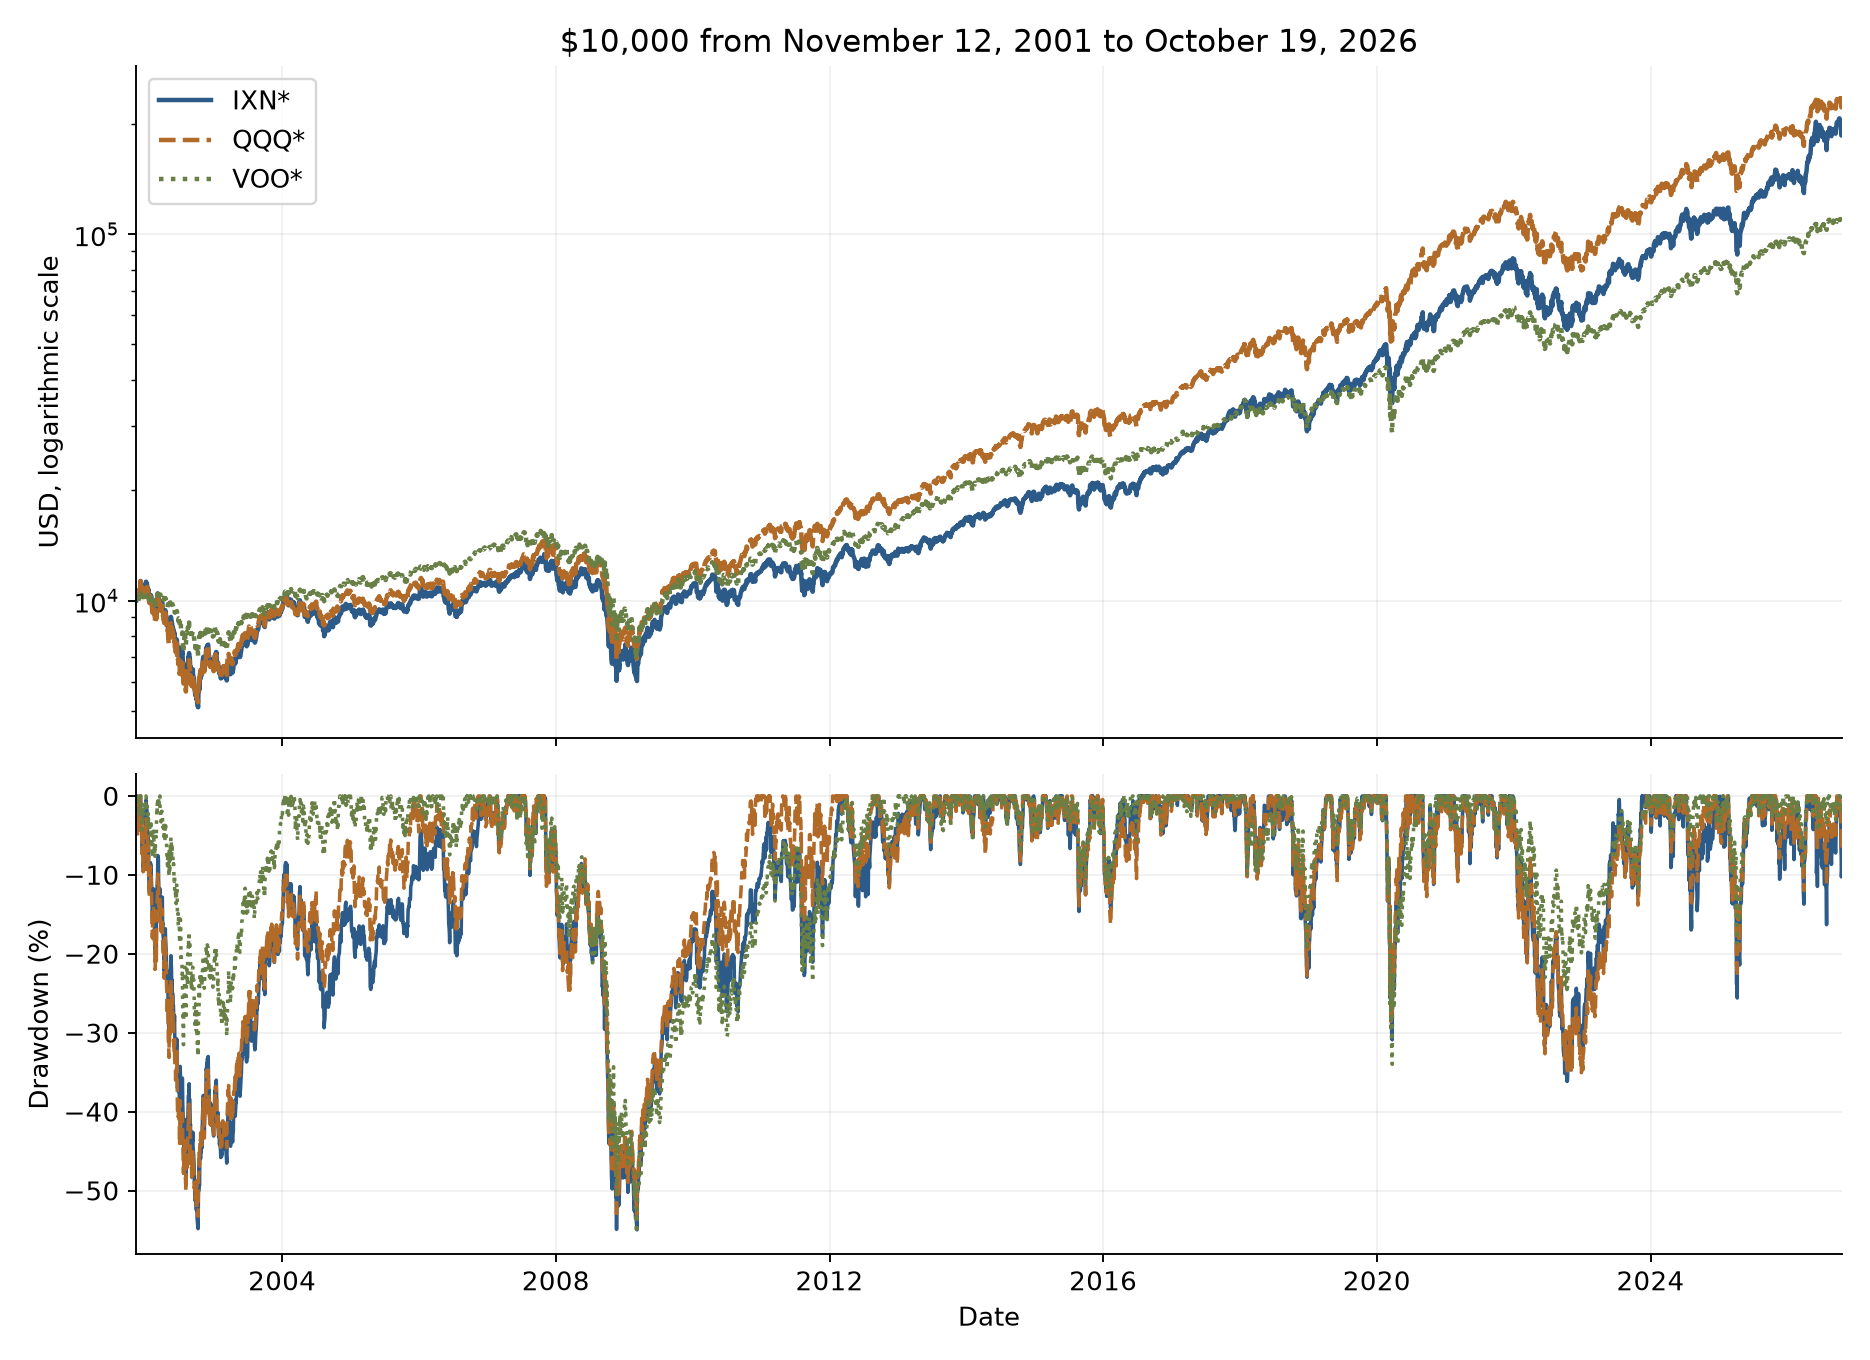

In [3]:
levels=analyze.LEVELS.loc[analyze.LAUNCH:]
fig, axs=plt.subplots(2,1,figsize=(11,8),sharex=True,gridspec_kw={'height_ratios':[1.4,1]})
for i,n in enumerate(levels):
    wealth=10000*levels[n]/levels[n].iloc[0]
    axs[0].plot(wealth.index,wealth,color=colors[i],label=analyze.SHORT[n],linestyle=['-','--',':'][i],lw=1.9)
    axs[1].plot(wealth.index,(wealth/wealth.cummax()-1)*100,color=colors[i],linestyle=['-','--',':'][i],lw=1.5)
axs[0].set_yscale('log');axs[0].set_ylabel('USD, logarithmic scale');axs[0].set_title('$10,000 from November 12, 2001 to October 19, 2026');axs[0].legend()
axs[1].set_ylabel('Drawdown (%)');axs[1].set_xlabel('Date');axs[1].set_xlim(levels.index[0],levels.index[-1])
fig.tight_layout();fig.savefig('history-and-drawdowns.png',dpi=170);display(Image(filename='history-and-drawdowns.png'));plt.close(fig)


### Current concentration
More names do not imply more equal weight or less exposure to a shared economic shock. VOO holdings have a different snapshot date.

In [4]:
display(pd.DataFrame(results['concentration']).round(4))
display(pd.DataFrame(results['overlap']).T.round(4))
print('Daily-return correlations since launch:')
display(pd.DataFrame(results['risk']['IXN inception']['correlations']).round(3))


,fund,snapshot_date,equity_lines,issuers,equity_weight_total,hhi,effective_stocks,top3,top10_issuers,top10_lines
0,IXN,2026-10-16,130,129,0.9976,0.0574,17.4364,0.3677,0.6089,0.6049
1,QQQ,2026-10-16,101,100,0.9986,0.0337,29.6983,0.2231,0.4981,0.4707
2,VOO,2026-09-30,505,502,1.0013,0.0245,40.8443,0.2152,0.4057,0.3905


,weighted_overlap,ixn_weight_in_common_names
QQQ,0.5295,0.7087
VOO,0.3972,0.7716


Daily-return correlations since launch:


,IXN / prelaunch FSPTX,QQQ / prelaunch NDX price,VOO / prelaunch S&P TR
IXN / prelaunch FSPTX,1.000,0.948,0.878
QQQ / prelaunch NDX price,0.948,1.000,0.903
VOO / prelaunch S&P TR,0.878,0.903,1.000


### TSMC and ASML exclusion sensitivity
Constant modern weights and USD ADR/listed-share proxies. This does not establish the contribution of actual historical holdings. The same prelaunch technology proxy is retained for early starts.

,window,method,cagr,ending_10000
16,1990,Exclude and reallocate,0.1452,1.470603e+06
17,2000,Exclude and reallocate,0.0767,7.254906e+04
18,IXN inception,Exclude and reallocate,0.1174,1.591203e+05
19,2010,Exclude and reallocate,0.1765,1.534940e+05
20,1990,Replace removed sleeve with zero-return cash,0.1399,1.239739e+06
21,2000,Replace removed sleeve with zero-return cash,0.0699,6.115987e+04
22,IXN inception,Replace removed sleeve with zero-return cash,0.1097,1.341406e+05
23,2010,Replace removed sleeve with zero-return cash,0.1640,1.281453e+05


,weight_sensitivity,method,cagr,ending_10000
2,No removal,Exclude and reallocate,0.1250,188465.6767
6,No removal,Replace removed sleeve with zero-return cash,0.1250,188465.6767
10,Half current weights,Exclude and reallocate,0.1213,173837.4740
14,Half current weights,Replace removed sleeve with zero-return cash,0.1174,159246.8757
18,Current weights,Exclude and reallocate,0.1174,159120.3081
22,Current weights,Replace removed sleeve with zero-return cash,0.1097,134140.6454
26,Twice current weights,Exclude and reallocate,0.1082,129681.5921
30,Twice current weights,Replace removed sleeve with zero-return cash,0.0942,94293.1188


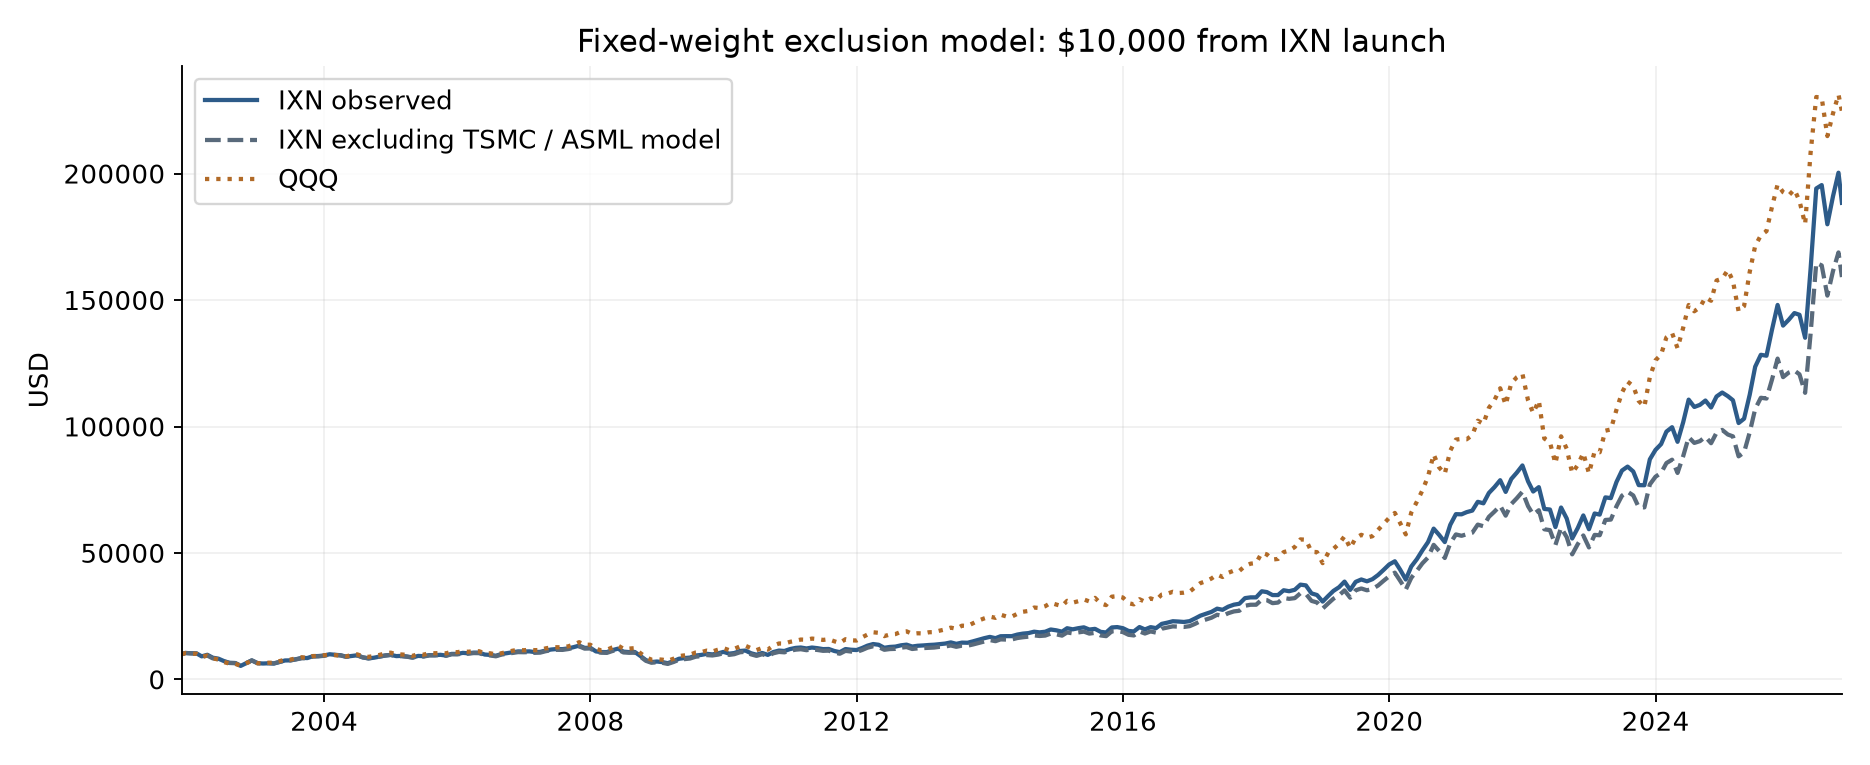

In [5]:
ex = pd.DataFrame(results['exclusion'])
display(ex.query("weight_sensitivity == 'Current weights'")[['window','method','cagr','ending_10000']].round(4))
display(ex.query("window == 'IXN inception'")[['weight_sensitivity','method','cagr','ending_10000']].round(4))
p=pd.read_csv('exclusion_monthly_paths.csv',index_col='date',parse_dates=True)*10000
fig,ax=plt.subplots(figsize=(11,4.5))
for i,n in enumerate(p):ax.plot(p.index,p[n],label=['IXN observed','IXN excluding TSMC / ASML model','QQQ'][i],color=[colors[0],'#596a7b',colors[1]][i],linestyle=['-','--',':'][i],lw=1.8)
ax.set_title('Fixed-weight exclusion model: $10,000 from IXN launch');ax.set_ylabel('USD');ax.set_xlim(p.index[0],p.index[-1]);ax.legend();fig.tight_layout();fig.savefig('exclusion.png',dpi=170);display(Image(filename='exclusion.png'));plt.close(fig)


### Hypothetical stock-count experiment
Common observed technology path plus assumed independent individual-stock noise. Bands represent only residual dispersion conditional on the observed common path.

,window,stocks,paths,median_ending_10000,p05_ending_10000,p95_ending_10000,median_cagr,median_volatility
0,1990,100,5000,1.727981e+06,1.276265e+06,2.321663e+06,0.1503,0.2578
1,1990,130,5000,1.732758e+06,1.328280e+06,2.244521e+06,0.1503,0.2574
2,1990,500,5000,1.742846e+06,1.521596e+06,1.987781e+06,0.1505,0.2565
3,1990,1200,5000,1.743787e+06,1.597435e+06,1.898224e+06,0.1505,0.2563
4,2000,100,5000,8.465196e+04,6.562533e+04,1.096025e+05,0.0830,0.2534
5,2000,130,5000,8.491847e+04,6.793120e+04,1.065242e+05,0.0831,0.2530
6,2000,500,5000,8.562050e+04,7.641344e+04,9.611545e+04,0.0834,0.2520
7,2000,1200,5000,8.577777e+04,7.970645e+04,9.242440e+04,0.0835,0.2518
8,IXN inception,100,5000,1.869273e+05,1.448370e+05,2.365008e+05,0.1246,0.2086
9,IXN inception,130,5000,1.873442e+05,1.497896e+05,2.302435e+05,0.1247,0.2081


,rho,stocks,stock_volatility,portfolio_volatility
0,0.2,100,0.35,0.15962
1,0.2,130,0.35,0.15891
2,0.2,500,0.35,0.15715
3,0.2,1200,0.35,0.15679
4,0.6,100,0.35,0.27201
5,0.6,130,0.35,0.27180
6,0.6,500,0.35,0.27129
7,0.6,1200,0.35,0.27118
8,0.8,100,0.35,0.31344
9,0.8,130,0.35,0.31335


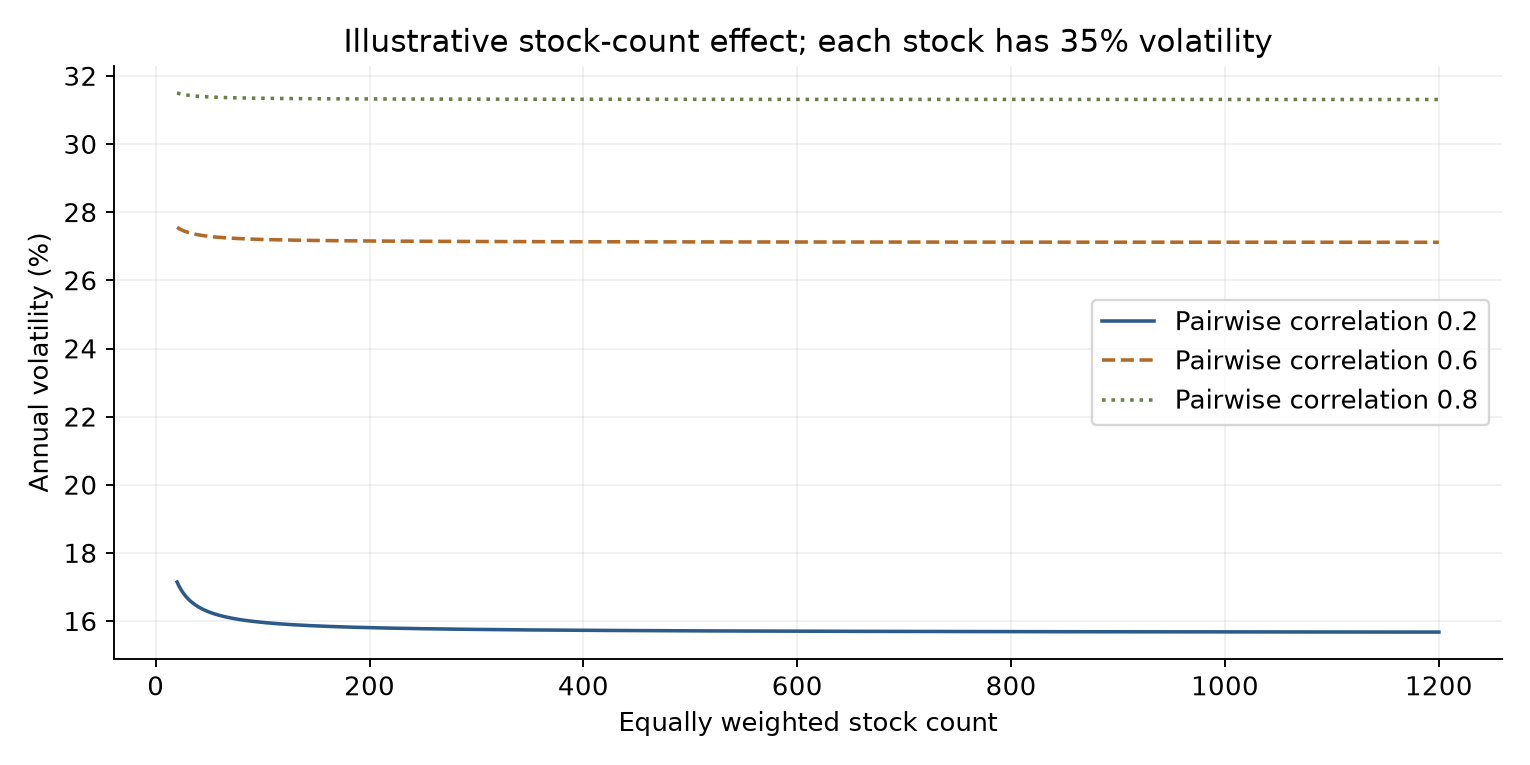

In [6]:
display(pd.DataFrame(results['diversification']).round(4))
theory=pd.DataFrame(results['equicorrelation'])
display(theory.round(5))
fig,ax=plt.subplots(figsize=(9,4.5))
for j,rho in enumerate([.2,.6,.8]):
    n=np.arange(20,1201)
    ax.plot(n,35*np.sqrt(rho+(1-rho)/n),color=colors[j],label=f'Pairwise correlation {rho}',linestyle=['-','--',':'][j])
ax.set_xlabel('Equally weighted stock count');ax.set_ylabel('Annual volatility (%)');ax.set_title('Illustrative stock-count effect; each stock has 35% volatility');ax.legend();fig.tight_layout();fig.savefig('diversification.png',dpi=170);display(Image(filename='diversification.png'));plt.close(fig)


### Rolling observations and paired historical bootstrap
All calibration windows are in the CSV. The table below highlights inception calibration. These are backward-looking distributions, not AI return forecasts.

In [7]:
display(pd.DataFrame(results['rolling']).round(4))
boot=pd.DataFrame(results['bootstrap'])
display(boot.query("calibration_window == 'IXN inception'").round(4))


,years,fund,observations,median_cagr,worst_cagr,best_cagr,ixn_beats_qqq_fraction
0,1,IXN*,287,0.1534,-0.4497,0.7241,0.3972
1,1,QQQ*,287,0.1879,-0.4307,0.6842,0.3972
2,1,VOO*,287,0.1420,-0.4334,0.5647,0.3972
3,3,IXN*,263,0.1399,-0.1467,0.4006,0.3726
4,3,QQQ*,263,0.1589,-0.1222,0.3799,0.3726
5,3,VOO*,263,0.1190,-0.1513,0.2603,0.3726
6,5,IXN*,239,0.1481,-0.0798,0.2969,0.3556
7,5,QQQ*,239,0.1619,-0.0509,0.2834,0.3556
8,5,VOO*,239,0.1195,-0.0666,0.2296,0.3556
9,10,IXN*,179,0.1534,0.0116,0.2542,0.2402


,calibration_window,horizon_years,fund,paths,p05_cagr,median_cagr,p95_cagr,loss_fraction,ixn_beats_qqq_fraction
24,IXN inception,1,IXN*,10000,-0.2809,0.1542,0.5226,0.1960,0.4028
25,IXN inception,1,QQQ*,10000,-0.2706,0.1899,0.4806,0.1471,0.4028
26,IXN inception,1,VOO*,10000,-0.2200,0.1433,0.3382,0.1711,0.4028
27,IXN inception,3,IXN*,10000,-0.0916,0.1476,0.3502,0.1444,0.3333
28,IXN inception,3,QQQ*,10000,-0.0707,0.1643,0.3436,0.1262,0.3333
29,IXN inception,3,VOO*,10000,-0.0731,0.1218,0.2479,0.1439,0.3333
30,IXN inception,5,IXN*,10000,-0.0357,0.1402,0.2999,0.0950,0.2943
31,IXN inception,5,QQQ*,10000,-0.0182,0.1549,0.3002,0.0712,0.2943
32,IXN inception,5,VOO*,10000,-0.0307,0.1152,0.2201,0.0907,0.2943
33,IXN inception,10,IXN*,10000,0.0145,0.1373,0.2513,0.0342,0.2281


### Technical and fee calculations

In [8]:
tech=pd.DataFrame(results['technicals'])
display(tech[['fund','asof','close','sma20','sma50','sma200','rsi14','macd','signal','histogram','atr14','realized_vol63']].round(3))
display(pd.DataFrame(results['fees']).round(4))


,fund,asof,close,sma20,sma50,sma200,rsi14,macd,signal,histogram,atr14,realized_vol63
0,IXN,2026-10-19,139.26,147.545,143.676,126.488,37.331,-0.654,1.028,-1.683,2.879,0.264
1,QQQ,2026-10-19,718.36,741.364,726.680,675.429,41.147,-0.011,4.931,-4.942,10.846,0.186
2,VOO,2026-10-19,704.60,708.905,706.501,667.073,47.013,0.971,1.970,-0.998,6.480,0.110


,years,fund,fee,annual_gross_assumption,ending_100000,loss_vs_no_fee
0,1,IXN,0.0037,0.08,107600.4000,399.6000
1,1,QQQ,0.0018,0.08,107805.6000,194.4000
2,1,VOO,0.0003,0.08,107967.6000,32.4000
3,1,QQQM,0.0015,0.08,107838.0000,162.0000
4,3,IXN,0.0037,0.08,124578.0869,1393.1131
5,3,QQQ,0.0018,0.08,125292.1792,679.0208
6,3,VOO,0.0003,0.08,125857.8599,113.3401
7,3,QQQM,0.0015,0.08,125405.1795,566.0205
8,5,IXN,0.0037,0.08,144234.5916,2698.2161
9,5,QQQ,0.0018,0.08,145615.1645,1317.6432


### Validation
The issuer reconciliation covers all 298 comparable monthly observations. Small differences remain between daily NAV arithmetic and the separately published monthly series. These are retained rather than forced to match.

In [9]:
print(results['reconciliation'])
assert analyze.LEVELS.loc['1989-12-29':].notna().all().all()
assert analyze.LEVELS.index.is_unique
assert analyze.LEVELS.index[-1] == pd.Timestamp('2026-10-19')
assert all(x['effective_stocks'] <= x['issuers'] for x in results['concentration'])
assert all(0 <= x['ixn_beats_qqq_fraction'] <= 1 for x in results['bootstrap'])
assert results['reconciliation']['largest_abs_monthly_error_bp'] < 3
assert abs(float(analyze.IXN_NAV.loc['2026-09-30']) - 20.0364) < .003
checks={'daily_dates_unique':True,'all_series_end':'2026-10-19','no_missing_analysis_levels':True,'max_monthly_nav_discrepancy_bp':results['reconciliation']['largest_abs_monthly_error_bp'],'official_sept2026_cumulative_wealth_multiple':20.0364,'reconstructed_multiple':float(analyze.IXN_NAV.loc['2026-09-30'])}
Path('validation.json').write_text(__import__('json').dumps(checks,indent=2))
display(checks)


{'months_checked': 298, 'largest_abs_monthly_error_bp': np.float64(2.7484985682785235), 'nav_bridge_date': '2026-10-19', 'nav_bridge_return': 0.01375845859233027}


{'daily_dates_unique': True,
 'all_series_end': '2026-10-19',
 'no_missing_analysis_levels': True,
 'max_monthly_nav_discrepancy_bp': np.float64(2.7484985682785235),
 'official_sept2026_cumulative_wealth_multiple': 20.0364,
 'reconstructed_multiple': 20.03807605042462}

## Takeaways
QQQ has the stronger full common-history record and a lower fee. IXN offers a more concentrated global technology/supplier tilt, including direct TSMC and Korean semiconductor exposure. VOO has the broadest sector coverage and lowest fee. None of these historical or synthetic experiments proves which fund will outperform in the AI economy. Exact prelaunch IXN and exact historical constituent removal remain unavailable.

The 1990 results compare proxies; they are unsuitable as a precise ranking of today’s funds. The 2000 window makes the cost of valuation and technology regime risk visible.